# Análise Exploratória de Dados (AED)

Este notebook foi criado para organizar a análise exploratória dos dados do projeto. Os objetivos são:  (1) Entender estrutura e qualidade dos dados; (2) Identificar padrões iniciais e possíveis outliers; e (3) Preparar insights para etapas posteriores do projeto.

### Introdução

A Aventura é uma produtora e gestora cultural referência no Brasil, com forte atuação na criação de espetáculos e na gestão de teatros, promovendo experiências artísticas de alta qualidade para diferentes públicos. Inserido nesse contexto, o projeto propõe o desenvolvimento de uma solução digital para o Portal Aventura, com foco em ampliar o alcance de seus conteúdos e fortalecer a conexão entre espectadores e o ecossistema cultural da empresa.

### Contextualização do Problema

Atualmente, o Portal Aventura não possui um sistema estruturado de recomendação de conteúdos e espetáculos. Dessa forma, a navegação do usuário ocorre principalmente a partir do acesso a páginas específicas, sem a apresecntação de sugestões relacionadas a outras experiências disponíveis no portal, o que pode reduzir o potencial de conversão e geração de receita.

### Objetivo do Sistema

O objetivo do sistema é desenvolver uma solução de recomendação inteligente capaz de sugerir espetáculos, conteúdos e experiências alinhadas aos interesses dos usuários. Com isso, busca-se aumentar o tempo de permanência no portal, estimular a navegação entre diferentes conteúdos e impulsionar a venda de ingressos, criando uma jornada mais conectada e personalizada dentro do ecossistema da Aventura.

# Importação dos dados e tratamento

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

sns.set_theme(style="whitegrid")

base_path = Path("../database_sympla.csv")

if not base_path.exists():
    raise FileNotFoundError(f"Arquivo não encontrado em: {base_path}")

df = pd.read_csv(base_path)

# Cópia para transformações de análise
df_eda = df.copy()

# Tratando vírgula/ponto e possíveis símbolos
df_eda["VALOR_NUM"] = (
    df_eda["VALOR DO INGRESSO"].astype(str)
    .str.replace(r"[^0-9,.-]", "", regex=True)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
)
df_eda["VALOR_NUM"] = pd.to_numeric(df_eda["VALOR_NUM"], errors="coerce")

# Conversão de datas
df_eda["DATA_APRESENTACAO_DT"] = pd.to_datetime(df_eda["DATA DA APRESENTAÇÃO"], errors="coerce")
df_eda["DATA_COMPRA_DT"] = pd.to_datetime(df_eda["DATA DA COMPRA"], errors="coerce")

# Antecedência de compra em dias (compra -> apresentação), arredondada para inteiro
df_eda["ANTECEDENCIA_DIAS"] = (
    (df_eda["DATA_APRESENTACAO_DT"] - df_eda["DATA_COMPRA_DT"]).dt.total_seconds() / 86400
).round().astype("Int64")

print(f"Linhas: {df_eda.shape[0]} | Colunas: {df_eda.shape[1]}")
df_eda.head()

C:\Users\Inteli\AppData\Local\Temp\ipykernel_33512\3155347632.py:29: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_eda["DATA_APRESENTACAO_DT"] = pd.to_datetime(df_eda["DATA DA APRESENTAÇÃO"], errors="coerce")
C:\Users\Inteli\AppData\Local\Temp\ipykernel_33512\3155347632.py:30: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_eda["DATA_COMPRA_DT"] = pd.to_datetime(df_eda["DATA DA COMPRA"], errors="coerce")


Linhas: 343758 | Colunas: 14


,ID COMPRADOR.1.ID USUÁRIO,NOME ESPETÁCULO,TEATRO,DATA DA APRESENTAÇÃO,DATA DA COMPRA,SETOR,VALOR DO INGRESSO,MÉTODO DE PAGAMENTO,CANAL DA VENDA,TIPO,VALOR_NUM,DATA_APRESENTACAO_DT,DATA_COMPRA_DT,ANTECEDENCIA_DIAS
0,1,UM MALLANDRO NA QUARENTENA COM SERGIO MALLANDRO,TEATRO RIACHUELO RJ,6/26/21 20:00,5/20/21 5:03,PLATEIA VIP - 02 PESSOAS,120,BOLETO,WEB,Show Stand-Up,120.0,2021-06-26 20:00:00,2021-05-20 05:03:00,38
1,1,UM MALLANDRO NA QUARENTENA COM SERGIO MALLANDRO,TEATRO RIACHUELO RJ,6/26/21 20:00,5/20/21 5:03,PLATEIA VIP - 02 PESSOAS,120,BOLETO,WEB,Show Stand-Up,120.0,2021-06-26 20:00:00,2021-05-20 05:03:00,38
2,2,DOMINGUINHOS - ISSO AQUI TÁ BOM DEMAIS,TEATRO RIACHUELO RJ,6/9/23 20:00,6/9/23 10:04,BALCÃO,50,CARTAO DE CREDITO,WEB,Show Musical,50.0,2023-06-09 20:00:00,2023-06-09 10:04:00,0
3,2,DOMINGUINHOS - ISSO AQUI TÁ BOM DEMAIS,TEATRO RIACHUELO RJ,6/9/23 20:00,6/9/23 10:04,BALCÃO,50,CARTAO DE CREDITO,WEB,Show Musical,50.0,2023-06-09 20:00:00,2023-06-09 10:04:00,0
4,3,A NOVIÇA REBELDE,TEATRO RIACHUELO RJ,5/11/24 19:00,5/10/24 20:33,PLATEIA,225,CARTAO DE CREDITO,WEB,Espetáculo Musical,225.0,2024-05-11 19:00:00,2024-05-10 20:33:00,1


## Criação do dataset para sistema de recomendação

In [2]:
# CRIAÇÃO DO DATASET PARA CF (FILTRAGEM COLABORATIVA)

# Selecionar colunas necessárias
df_rec = df_eda[
    [
        "ID COMPRADOR.1.ID USUÁRIO",
        "NOME ESPETÁCULO",
        "DATA_COMPRA_DT",
        "VALOR_NUM",
        "TIPO"
    ]
].copy()

# Remover nulos essenciais
df_rec = df_rec.dropna(subset=["ID COMPRADOR.1.ID USUÁRIO", "NOME ESPETÁCULO", "DATA_COMPRA_DT"])

# Padronizar texto
df_rec["NOME ESPETÁCULO"] = df_rec["NOME ESPETÁCULO"].astype(str).str.strip()
df_rec["TIPO"] = df_rec["TIPO"].astype(str).str.strip()

# Criar uma coluna apenas com a data da compra, sem horário
df_rec["DATA_COMPRA_DIA"] = pd.to_datetime(
    df_rec["DATA_COMPRA_DT"],
    errors="coerce"
).dt.date

df_rec = df_rec.dropna(subset=["DATA_COMPRA_DIA"])

# Regra de interação:
# compras do mesmo usuário, mesmo espetáculo e mesma data contam como apenas 1 interação
df_rec_interacoes = df_rec.drop_duplicates(
    subset=[
        "ID COMPRADOR.1.ID USUÁRIO",
        "NOME ESPETÁCULO",
        "DATA_COMPRA_DIA"
    ]
)

print("Registros antes da regra de interação:", len(df_rec))
print("Registros depois da regra de interação:", len(df_rec_interacoes))
print("Registros removidos pela regra:", len(df_rec) - len(df_rec_interacoes))

# AGRUPAMENTO
dataset = (
    df_rec_interacoes
    .groupby(["ID COMPRADOR.1.ID USUÁRIO", "NOME ESPETÁCULO"])
    .agg(
        ranking=("DATA_COMPRA_DIA", "nunique"),
        valor_medio_ingresso=("VALOR_NUM", "mean"),
        tipo_evento=("TIPO", "first")
    )
    .reset_index()
)

# Limitar o ranking máximo em 5 para reduzir impacto de outliers
dataset["ranking"] = dataset["ranking"].clip(upper=5)

print("Distribuição do ranking após limite máximo em 5:")
print(dataset["ranking"].value_counts().sort_index())

print("\nRanking máximo encontrado:", dataset["ranking"].max())

# PADRONIZAÇÃO FINAL
dataset = dataset.rename(columns={
    "ID COMPRADOR.1.ID USUÁRIO": "user_id",
    "NOME ESPETÁCULO": "item_id"
})

dataset = dataset[
    ["user_id", "item_id", "ranking", "valor_medio_ingresso", "tipo_evento"]
]


# Salvar CSV
output_path = Path("../dataset/dataset.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

dataset.to_csv(output_path, index=False)

print("Dataset salvo em:", output_path)
dataset.head()

Registros antes da regra de interação: 343757
Registros depois da regra de interação: 126239
Registros removidos pela regra: 217518
Distribuição do ranking após limite máximo em 5:
ranking
1    105337
2      5843
3       645
4       146
5       376
Name: count, dtype: int64

Ranking máximo encontrado: 5
Dataset salvo em: ..\dataset\dataset.csv


,user_id,item_id,ranking,valor_medio_ingresso,tipo_evento
0,1,UM MALLANDRO NA QUARENTENA COM SERGIO MALLANDRO,1,120.0,Show Stand-Up
1,2,DOMINGUINHOS - ISSO AQUI TÁ BOM DEMAIS,1,50.0,Show Musical
2,3,A NOVIÇA REBELDE,1,225.0,Espetáculo Musical
3,4,MUSICAL HAIRSPRAY,1,350.0,Espetáculo Musical
4,5,A NOVIÇA REBELDE,1,125.0,Espetáculo Musical


## Carregamento do dataset final

In [3]:
df_dataset = pd.read_csv("../dataset/dataset.csv")
df_dataset.head()

,user_id,item_id,ranking,valor_medio_ingresso,tipo_evento
0,1,UM MALLANDRO NA QUARENTENA COM SERGIO MALLANDRO,1,120.0,Show Stand-Up
1,2,DOMINGUINHOS - ISSO AQUI TÁ BOM DEMAIS,1,50.0,Show Musical
2,3,A NOVIÇA REBELDE,1,225.0,Espetáculo Musical
3,4,MUSICAL HAIRSPRAY,1,350.0,Espetáculo Musical
4,5,A NOVIÇA REBELDE,1,125.0,Espetáculo Musical


## 1) Descrição do dataset final de recomendação

Nesta etapa, analisamos a estrutura do dataset final utilizado como base para o sistema de recomendação da Aventura.

O objetivo é verificar se a base está adequada para representar as interações entre usuários e espetáculos, considerando os tratamentos aplicados anteriormente. Como a base original não possui avaliações explícitas, o `ranking` foi construído como uma medida de feedback implícito, representando a quantidade de dias distintos em que um usuário interagiu com determinado espetáculo, com limite máximo de 5.

Essa etapa responde:

- Quantas linhas e colunas existem no dataset?
- O que cada variável representa?
- Existem dados faltantes?
- Há registros duplicados?
- Como o `ranking` está distribuído após os tratamentos?
- A base está adequada para a próxima etapa de preparação da matriz usuário-item?

In [4]:
print(f"Dimensão do dataset final: {df_dataset.shape[0]:,} linhas x {df_dataset.shape[1]} colunas".replace(",", "."))

dicionario = pd.DataFrame(
    {
        "Variável": [
            "user_id",
            "item_id",
            "ranking",
            "valor_medio_ingresso",
            "tipo_evento",
        ],
        "Descrição": [
            "Identificador único do usuário/comprador.",
            "Identificador do item recomendado, representado pelo nome do espetáculo.",
            "Quantidade de dias distintos em que o usuário interagiu com o espetáculo, limitada ao máximo de 5, usada como feedback implícito.",
            "Valor médio pago pelo usuário naquele espetáculo.",
            "Categoria ou tipo do evento associado ao espetáculo.",
        ],
    }
)

dicionario

Dimensão do dataset final: 112.347 linhas x 5 colunas


,Variável,Descrição
0,user_id,Identificador único do usuário/comprador.
1,item_id,"Identificador do item recomendado, representad..."
2,ranking,Quantidade de dias distintos em que o usuário ...
3,valor_medio_ingresso,Valor médio pago pelo usuário naquele espetáculo.
4,tipo_evento,Categoria ou tipo do evento associado ao espet...


In [5]:
faltantes = pd.DataFrame(
    {
        "qtd_faltante": df_dataset.isna().sum(),
        "perc_faltante": (df_dataset.isna().mean() * 100).round(4),
    }
).sort_values("qtd_faltante", ascending=False)

print("Total de linhas duplicadas:", df_dataset.duplicated().sum())

print(
    "Total de pares usuário-item duplicados:",
    df_dataset.duplicated(subset=["user_id", "item_id"]).sum()
)

print("Ranking máximo encontrado:", df_dataset["ranking"].max())

faltantes

Total de linhas duplicadas: 0
Total de pares usuário-item duplicados: 0
Ranking máximo encontrado: 5


,qtd_faltante,perc_faltante
user_id,0,0.0
item_id,0,0.0
ranking,0,0.0
valor_medio_ingresso,0,0.0
tipo_evento,0,0.0


## 2) Estatísticas descritivas do dataset final

In [6]:
df_dataset.describe(include="all")

,user_id,item_id,ranking,valor_medio_ingresso,tipo_evento
count,112347.000000,112347,112347.000000,112347.000000,112347
unique,NaN,571,NaN,NaN,8
top,NaN,A NOVIÇA REBELDE,NaN,NaN,Espetáculo Teatral
freq,NaN,8636,NaN,NaN,30412
mean,34449.023516,NaN,1.080777,63.043173,NaN
std,20020.462071,NaN,0.365641,42.696195,NaN
min,1.000000,NaN,1.000000,0.000000,NaN
25%,17062.000000,NaN,1.000000,35.000000,NaN
50%,34126.000000,NaN,1.000000,50.000000,NaN
75%,52107.500000,NaN,1.000000,80.000000,NaN


## 3) Análise de Balanceamento e Diagnóstico da Matriz

O sucesso de um modelo de filtragem colaborativa depende da qualidade das interações entre usuários e itens. Nesta seção, analisamos se o dataset final está adequado para ser utilizado futuramente em modelos de recomendação.

A preparação considera quatro pontos principais:

1. **Tratamento das interações:** compras repetidas do mesmo usuário para o mesmo espetáculo na mesma data foram consideradas como uma única interação.
2. **Controle de outliers no ranking:** o valor máximo do `ranking` foi limitado a 5, evitando que usuários com muitas interações distorçam a base.
3. **Esparsidade da matriz usuário-item:** calculamos o percentual de células vazias na relação entre usuários e espetáculos.
4. **Popularidade do catálogo:** avaliamos se o consumo está concentrado em poucos espetáculos ou se existe diversidade de itens consumidos.

In [7]:
# Métricas de Matriz
n_users = df_dataset["user_id"].nunique()
n_items = df_dataset["item_id"].nunique()
n_ratings = len(df_dataset)

# Cálculo de Esparsidade
rating_matrix_size = n_users * n_items
sparsity = (1 - n_ratings / rating_matrix_size) * 100

print(f"--- Métricas de Matriz Usuário-Item ---")
print(f"Número de usuários únicos: {n_users}")
print(f"Número de itens únicos: {n_items}")
print(f"Total de interações: {n_ratings}")
print(f"Esparsidade da matriz: {sparsity:.4f}%")

# Verificação de desbalanceamento de ranking
print("\n--- Proporção de Ranking (Dias distintos de interação) ---")
print(df_dataset["ranking"].value_counts(normalize=True).map('{:.2%}'.format))

--- Métricas de Matriz Usuário-Item ---
Número de usuários únicos: 68564
Número de itens únicos: 571
Total de interações: 112347
Esparsidade da matriz: 99.7130%

--- Proporção de Ranking (Dias distintos de interação) ---
ranking
1    93.76%
2     5.20%
3     0.57%
5     0.33%
4     0.13%
Name: proportion, dtype: object


### 3.1) Diagnóstico da Matriz Usuário-Item

A **esparsidade** calculada acima indica o percentual de interações "vazias" que o nosso modelo precisará prever. Em datasets de entretenimento e cultura, uma alta esparsidade é comum. Isso justifica o uso futuro de modelos de **Fatoração de Matrizes (SVD)** ou **Filtragem Colaborativa baseada em Vizinhos**, que são eficazes em encontrar padrões mesmo quando os usuários possuem poucas interações documentadas.

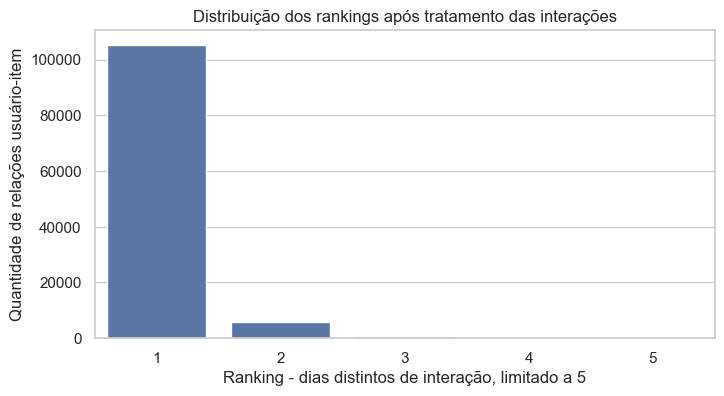

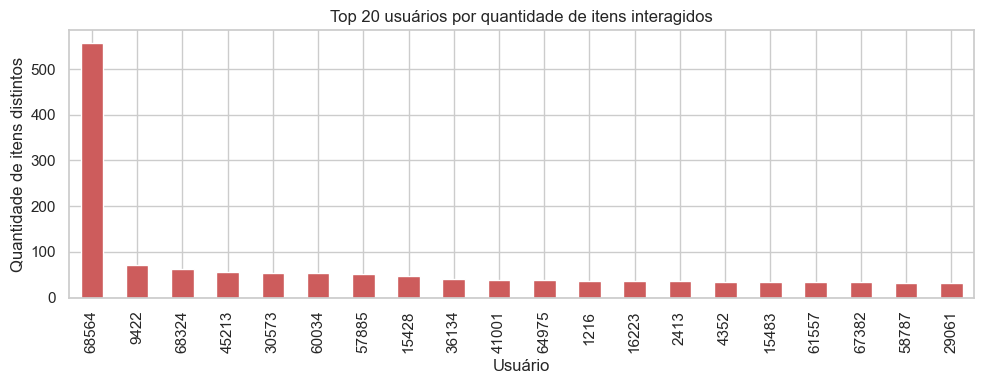

In [8]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df_dataset, x="ranking")
plt.title("Distribuição dos rankings após tratamento das interações")
plt.xlabel("Ranking - dias distintos de interação, limitado a 5")
plt.ylabel("Quantidade de relações usuário-item")
plt.show()

plt.figure(figsize=(10, 4))
df_dataset["user_id"].value_counts().head(20).plot(kind="bar", color="indianred")
plt.title("Top 20 usuários por quantidade de itens interagidos")
plt.xlabel("Usuário")
plt.ylabel("Quantidade de itens distintos")
plt.tight_layout()
plt.show()

- No Gráfico de distribuição dos rankings mostra forte concentração no valor 1, indicando que a maioria dos usuários interagiu com cada espetáculo em apenas um dia distinto. Existem poucas relações com ranking 2 e praticamente nenhuma com valores acima disso.
Esse comportamento é esperado em bases de compra de ingressos, pois normalmente um usuário compra determinado espetáculo uma única vez. A limitação do ranking ao valor máximo de 5 garante que interações muito altas não distorçam os modelos futuros.

- O gráfico dos usuários com maior quantidade de itens interagidos evidencia a presença de um usuário com comportamento muito acima do padrão da base. Esse tipo de perfil pode representar uma conta institucional, operacional ou um comportamento atípico, e por isso precisa ser analisado com cuidado.
A identificação desses usuários é importante porque, em modelos de filtragem colaborativa, perfis hiperativos podem influenciar excessivamente a matriz usuário-item e distorcer as recomendações.

In [9]:
matriz_usuario_item = df_dataset.pivot_table(
    index="user_id",
    columns="item_id",
    values="ranking",
    fill_value=0
)

print("Formato da matriz usuário-item:", matriz_usuario_item.shape)

matriz_usuario_item.head()

Formato da matriz usuário-item: (68564, 571)


item_id,"""DUDA BRACK - CACO DE VIDRO""","""EU NÃO DIGO É NADA "" COM GLAUBER CUNHA","""MÚSICA, LETRA E DANÇA"" BABI XAVIER, CAROL FAZU E HELGA NEMETIK CANTAM MARINA","""TACY - RELICÁRIO DE CÁSSIA ELLER""","""TÁ EMBAÇADO"" COM FABIO RABIN",(1) LONGA JORNADA NOITE ADENTRO,33º PRÊMIO SHELL DE TEATRO,38ª FORMATURA DO PROJETO MINIEMPRESA,4 AMIGOS,5ª CONFERÊNCIA ESTADUAL DE CULTURA,...,ZABELÊ - “AUÊ” SESSION`S #TEATRORIACHUELO5ANOS,ZAQUIM,ZECA BALEIRO – JOSÉ,ZÉ IBARRA,ZÉ IBARRA E DORA MORELENBAUM NO SOMAMOS FESTIVAL,ZÉLIA DUNCAN- SEM TIRAR OS OLHOS DO MUNDO,ÁUREA MARTINS - SENHORA DAS FOLHAS,ÁUREA MARTINS – LANÇAMENTO DO DISCO “SENHORA DAS FOLHAS”,ÓPERA DE PEQUIM - CHINA NATIONAL PEKING OPERA COMPANY,“PARA LENNON & MCCARTNEY – OS BEATLES E O CLUBE DA ESQUINA”
user_id,,,,,,,,,,,,,,,,,,,,,
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


A matriz usuário-item foi criada com 68.564 usuários e 571 espetáculos. Cada linha representa um usuário, cada coluna representa um espetáculo e cada célula contém o valor do `ranking`, que indica a força da interação entre eles.

Os valores iguais a 0 indicam ausência de interação entre determinado usuário e espetáculo. A presença de muitos zeros confirma a alta esparsidade da matriz, uma característica comum em sistemas de recomendação, pois cada usuário consome apenas uma pequena parte do catálogo total.

Essa matriz ainda não representa o treinamento do modelo, mas valida que a base tratada já pode ser utilizada nas próximas etapas de filtragem colaborativa, especialmente em modelos baseados em similaridade, como KNN.

### 3.2) Tratamento complementar de outliers por volume de usuários

Para garantir a eficácia do sistema de recomendação da **Aventura**, aplicamos uma estratégia de balanceamento focada na integridade da matriz usuário-item através da **Trimagem baseada em Percentis (Quantile-based Trimming)**.

#### 1. O Problema: Outliers de Volume
Em sistemas de recomendação baseados em filtragem colaborativa, o desbalanceamento mais crítico ocorre quando há uma disparidade extrema no volume de interações por usuário. 
* **O Risco:** Usuários "hiperativos" (com centenas de compras) funcionam como ruído. Eles "puxam" os cálculos de similaridade para si, fazendo com que o modelo recomende apenas o que esse super-usuário consumiu, ignorando os padrões reais da maioria orgânica.
* **A Causa:** Geralmente, esses perfis representam contas institucionais, bots de coleta ou pontos de venda física, e não o comportamento de um espectador individual.

#### 2. A Técnica: Trimagem por Percentil 99,9%
Em vez de definir um limite fixo e arbitrário, utilizamos a estatística descritiva para encontrar o ponto de corte natural do dataset.

**Como a técnica funciona:**
1. **Ordenação:** Calculamos a frequência de consumo para cada ID de usuário.
2. **Cálculo do Percentil:** Estabelecemos o **percentil 99,9%** como o limite superior de comportamento "orgânico". 
3. **Ponto de Corte:** Este cálculo define que 99,9% dos usuários da base consumiram até um determinado número de itens. Qualquer valor acima disso é estatisticamente tratado como uma anomalia (outlier).
4. **Normalização:** Os usuários que compõem o 0,1% restante da pirâmide de consumo são removidos, limpando o sinal que será enviado ao modelo.

#### 3. Preservação da Cauda Longa (Long Tail)
O balanceamento não visa apenas remover o topo, mas proteger a base. A estratégia garante que, ao limpar os usuários hiperativos, não prejudiquemos a diversidade de itens.

* **Cabeça do Catálogo (Head):** Itens populares (hits) que o modelo aprende facilmente.
* **Cauda do Catálogo (Tail):** Espetáculos de nicho que possuem poucas avaliações.

A estratégia adotada permite que o modelo mantenha a **capacidade de descoberta (Discovery)**, pois ao remover o ruído dos super-usuários, os padrões de consumo dos usuários comuns sobre itens da "cauda" tornam-se mais visíveis e fáceis de aprender pelo algoritmo.

#### 4. Benefícios para o Modelo de Recomendação
* **Estabilização da Variância:** Reduz o erro médio ao evitar distorções nas distâncias vetoriais.
* **Personalização Real:** As recomendações passam a ser baseadas em comportamentos de pessoas reais.
* **Mitigação do Viés de Popularidade:** Impede que o sistema se torne um "top 10" viciado, permitindo recomendações mais assertivas e variadas.

In [10]:
# Definindo o limite de corte (Percentil 99.9)
limite_corte = df_dataset["user_id"].value_counts().quantile(0.999)

# Identificando usuários acima do limite
contagem_user = df_dataset["user_id"].value_counts()
usuarios_remover = contagem_user[contagem_user > limite_corte].index

# Criando o dataset balanceado
df_dataset_bal = df_dataset[~df_dataset["user_id"].isin(usuarios_remover)].copy()

# Salvando o dataset balanceado para o CSV final
df_dataset_bal.to_csv("../dataset/dataset.csv", index=False)

print(f"Usuários removidos (outliers): {list(usuarios_remover)}")
print(f"Volume original: {len(df_dataset)} | Volume pós-balanceamento: {len(df_dataset_bal)}")

Usuários removidos (outliers): [68564, 9422, 68324, 45213, 30573, 60034, 57885, 15428, 36134, 41001, 64975, 1216, 16223, 2413, 4352, 15483, 61557, 67382, 58787, 29061, 7136, 56360, 44114, 9940, 26088, 6825, 66939, 7434, 45916, 61948, 19441, 37671, 9230, 20410, 58129, 39419, 23707, 57849, 3797, 56639, 50280, 26242, 27460, 14888, 63261, 6374, 56349, 25324, 24504, 30071, 19756, 64990, 967, 55251, 58606, 21451, 55310, 54174, 68093, 43420, 11936, 39588, 28618, 15707, 29489]
Volume original: 112347 | Volume pós-balanceamento: 109916


C:\Users\Inteli\AppData\Local\Temp\ipykernel_33512\810682273.py:7: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


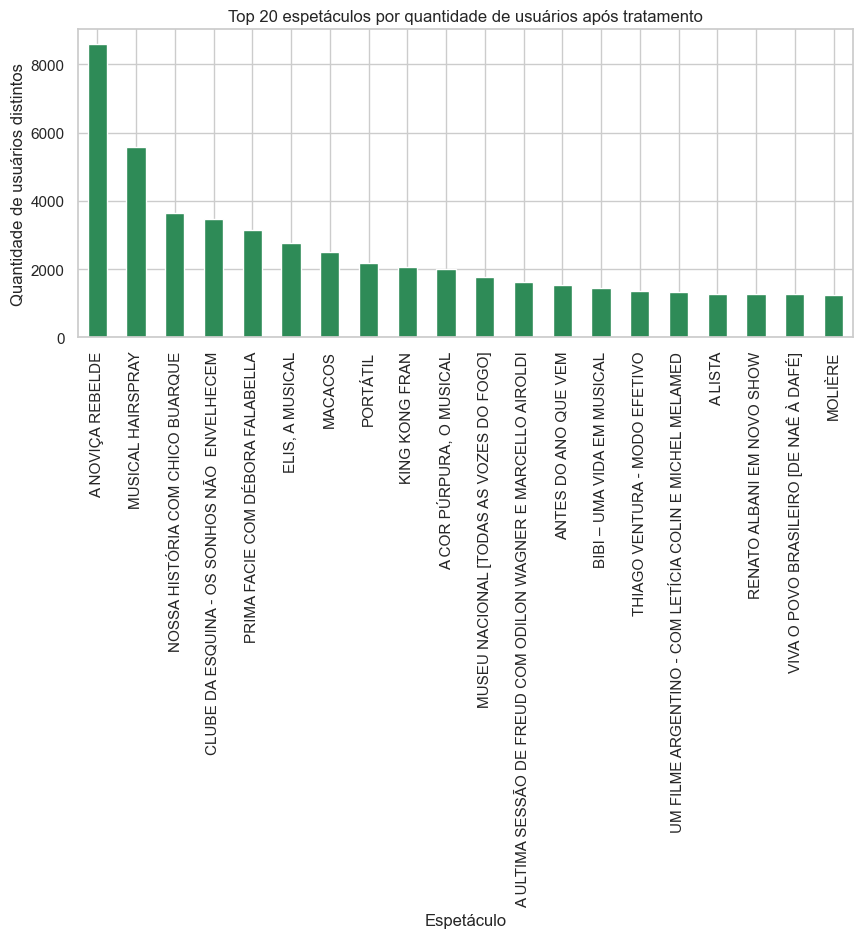

In [11]:
plt.figure(figsize=(10, 4))
df_dataset_bal["item_id"].value_counts().head(20).plot(kind="bar", color="seagreen")
plt.title("Top 20 espetáculos por quantidade de usuários após tratamento")
plt.xlabel("Espetáculo")
plt.ylabel("Quantidade de usuários distintos")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

O gráfico de popularidade dos espetáculos mostra que alguns itens concentram um número muito maior de usuários. Esse padrão indica uma distribuição desigual de consumo, com poucos espetáculos muito populares e muitos outros com menor volume de interação.

Essa característica reforça a importância de analisar a cauda longa do catálogo, pois um sistema de recomendação não deve apenas sugerir os itens mais populares, mas também ajudar na descoberta de espetáculos menos consumidos e potencialmente relevantes.

### 3.3) Validação: Curva de Cauda Longa (Long Tail)

Após a normalização, analisamos a distribuição do catálogo. Esperamos uma curva onde a "Cabeça" (itens hits) não abafe a capacidade do modelo de sugerir itens da "Cauda" (nicho), cumprindo a função de Discovery do portal Aventura.

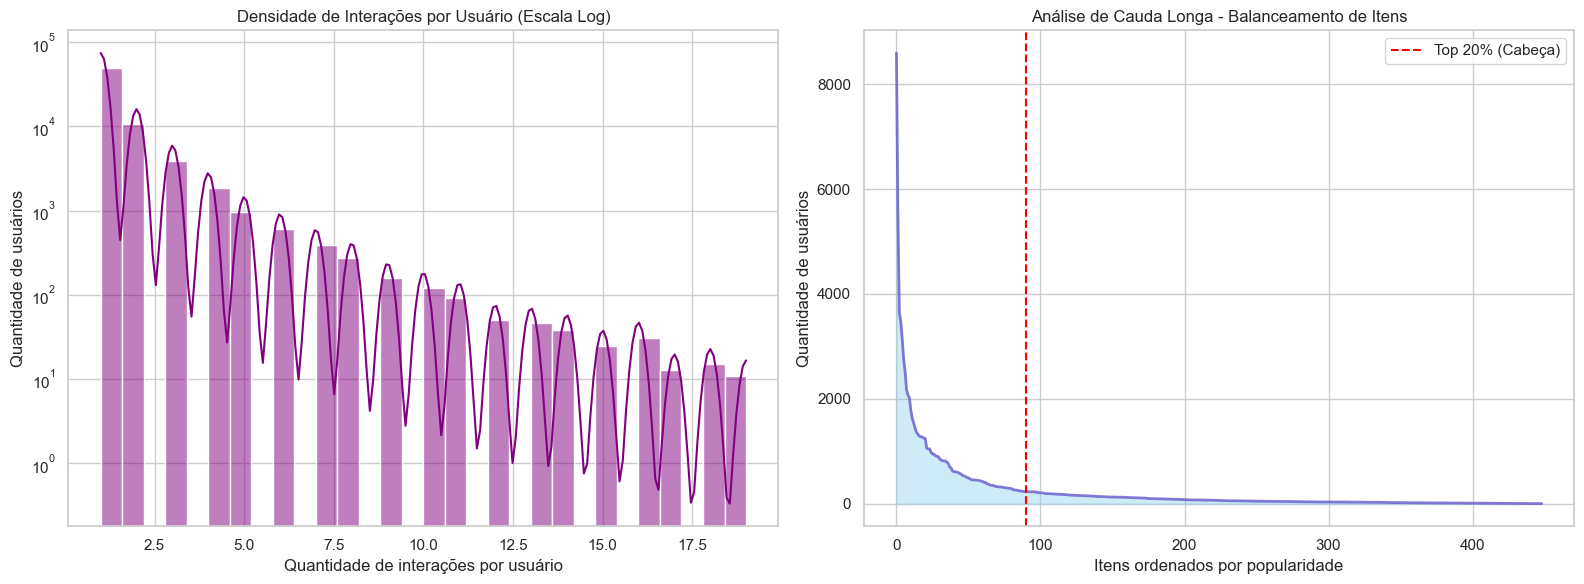

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Densidade Logarítmica
user_counts = df_dataset_bal.groupby("user_id").size()

sns.histplot(user_counts, bins=30, kde=True, ax=axes[0], color="purple")
axes[0].set_yscale("log")
axes[0].set_title("Densidade de Interações por Usuário (Escala Log)")
axes[0].set_xlabel("Quantidade de interações por usuário")
axes[0].set_ylabel("Quantidade de usuários")

# Gráfico 2: Curva de Cauda Longa
item_pop = df_dataset_bal.groupby("item_id").size().sort_values(ascending=False).reset_index()
item_pop.columns = ["item_id", "count"]

axes[1].fill_between(range(len(item_pop)), item_pop["count"], color="skyblue", alpha=0.4)
axes[1].plot(range(len(item_pop)), item_pop["count"], color="Slateblue", alpha=0.8, linewidth=2)
axes[1].axvline(x=len(item_pop) * 0.2, color="red", linestyle="--", label="Top 20% (Cabeça)")
axes[1].set_title("Análise de Cauda Longa - Balanceamento de Itens")
axes[1].set_xlabel("Itens ordenados por popularidade")
axes[1].set_ylabel("Quantidade de usuários")
axes[1].legend()

plt.tight_layout()
plt.show()

A distribuição de interações por usuário em escala logarítmica mostra que a maior parte dos usuários possui poucas interações, enquanto uma parcela pequena apresenta volume mais elevado. Esse comportamento é comum em bases reais de recomendação e indica uma distribuição assimétrica dos usuários.

A análise de cauda longa dos itens mostra que poucos espetáculos concentram grande quantidade de usuários, enquanto muitos itens possuem baixo volume de interação. Esse padrão reforça a importância de um sistema de recomendação que não sugira apenas os espetáculos mais populares, mas também ajude na descoberta de itens menos consumidos e potencialmente relevantes para cada perfil.

### 3.4) Conclusão da Qualidade do Dataset

Após a aplicação das técnicas de preparação dos dados, o dataset apresenta as seguintes garantias de qualidade:

- **Integridade das interações:** compras repetidas do mesmo usuário para o mesmo espetáculo na mesma data foram consideradas como uma única interação.
- **Controle de outliers:** o `ranking` foi limitado ao valor máximo de 5, reduzindo distorções causadas por interações muito altas.
- **Robustez estatística:** a análise de usuários com volume muito acima do padrão ajuda a reduzir ruídos na matriz usuário-item.
- **Prontidão para modelagem:** a base resultante está estruturada com `user_id`, `item_id` e `ranking`, estando adequada para as próximas etapas de filtragem colaborativa e fatoração de matrizes.

## 4) Análise complementar da base original

As análises abaixo utilizam a base original para complementar o entendimento dos dados, considerando variáveis que podem apoiar uma futura abordagem híbrida de recomendação.

### 4.1 Distribuição de preço

In [13]:
# Resumo estatístico do preço (unidade em R$)
resumo_preco = (
    df_eda["VALOR_NUM"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95])
    .to_frame("Preço (R$)")
    .round(2)
)
resumo_preco

,Preço (R$)
count,343757.00
mean,53.62
std,47.36
min,0.00
25%,20.00
50%,45.00
75%,75.00
90%,120.00
95%,140.00
max,360.00


### 4.2 Composição por tipo, teatro e canal de venda

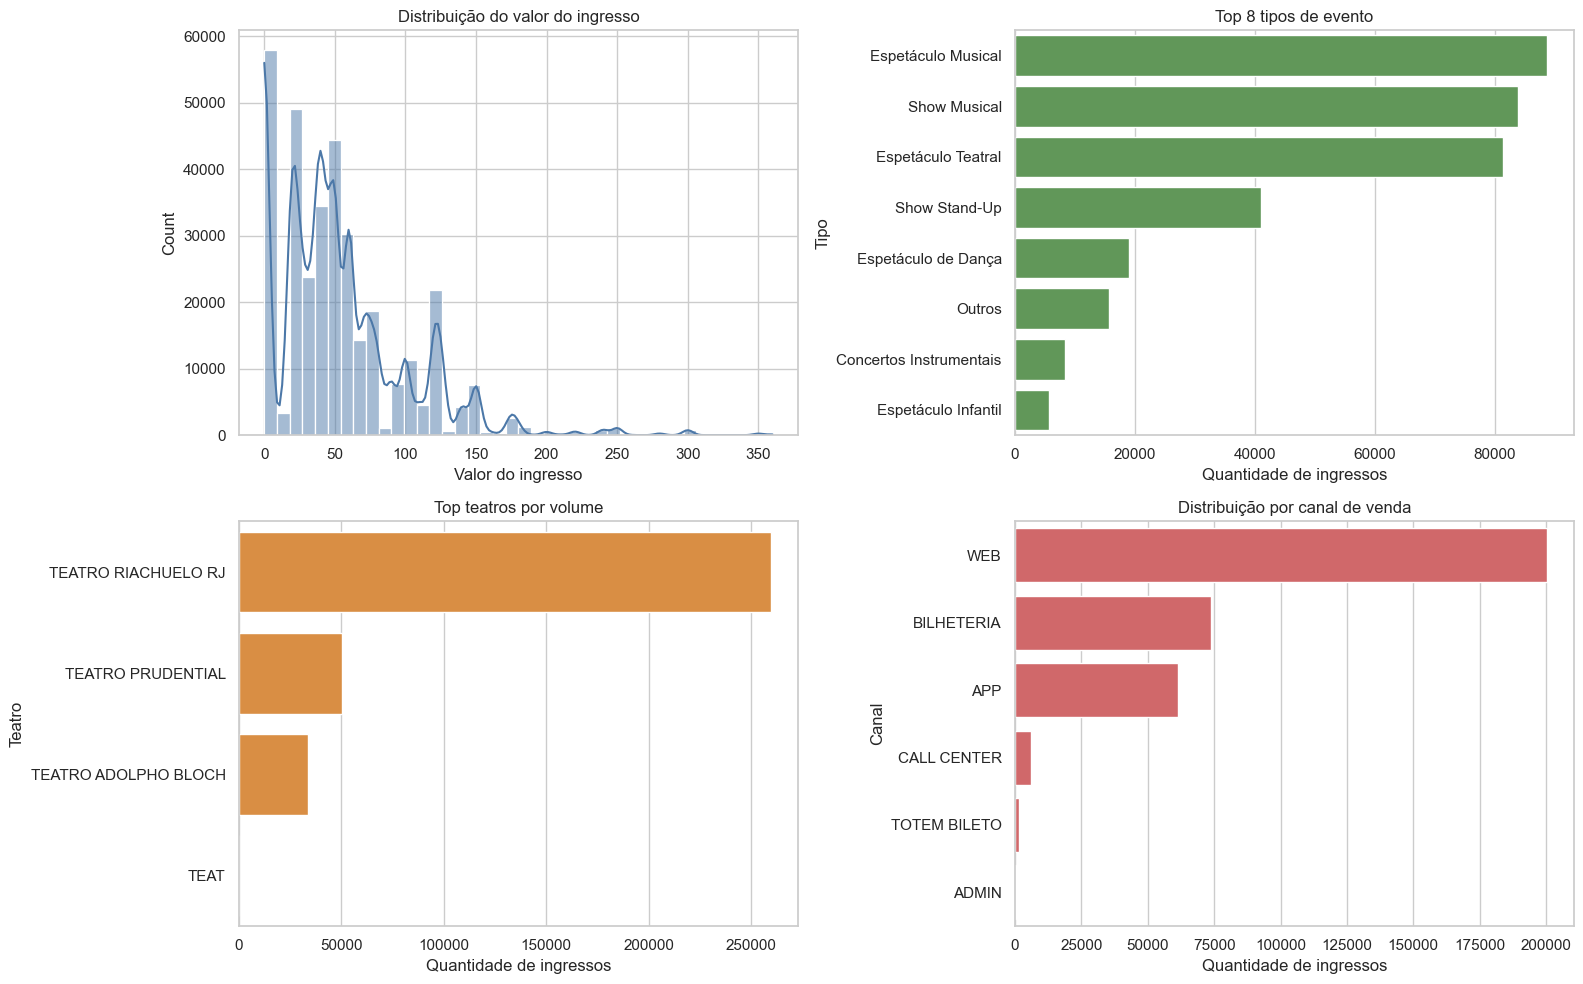

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Distribuição de valores
sns.histplot(df_eda["VALOR_NUM"].dropna(), bins=40, kde=True, ax=axes[0, 0], color="#4C78A8")
axes[0, 0].set_title("Distribuição do valor do ingresso")
axes[0, 0].set_xlabel("Valor do ingresso")

# Top tipos
top_tipos = df_eda["TIPO"].value_counts().head(8)
sns.barplot(x=top_tipos.values, y=top_tipos.index, ax=axes[0, 1], color="#59A14F")
axes[0, 1].set_title("Top 8 tipos de evento")
axes[0, 1].set_xlabel("Quantidade de ingressos")
axes[0, 1].set_ylabel("Tipo")

# Top teatros
top_teatros = df_eda["TEATRO"].value_counts().head(8)
sns.barplot(x=top_teatros.values, y=top_teatros.index, ax=axes[1, 0], color="#F28E2B")
axes[1, 0].set_title("Top teatros por volume")
axes[1, 0].set_xlabel("Quantidade de ingressos")
axes[1, 0].set_ylabel("Teatro")

# Canal de venda
canal_counts = df_eda["CANAL DA VENDA"].value_counts()
sns.barplot(x=canal_counts.values, y=canal_counts.index, ax=axes[1, 1], color="#E15759")
axes[1, 1].set_title("Distribuição por canal de venda")
axes[1, 1].set_xlabel("Quantidade de ingressos")
axes[1, 1].set_ylabel("Canal")

plt.tight_layout()
plt.show()

As análises complementares da base original ajudam a entender o contexto de consumo dos usuários. Observa-se variação nos valores dos ingressos, predominância de alguns tipos de evento, concentração de vendas em determinados teatros e forte presença do canal web.

Essas informações não são utilizadas diretamente nesta primeira preparação para filtragem colaborativa, mas podem apoiar futuras abordagens híbridas, combinando interações usuário-item com características dos eventos, como tipo, preço, teatro e canal de venda.

## 5) Análise bivariada complementar

Comportamento de compra e diferença de preço entre categorias.

C:\Users\Inteli\AppData\Local\Temp\ipykernel_33512\2926988402.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


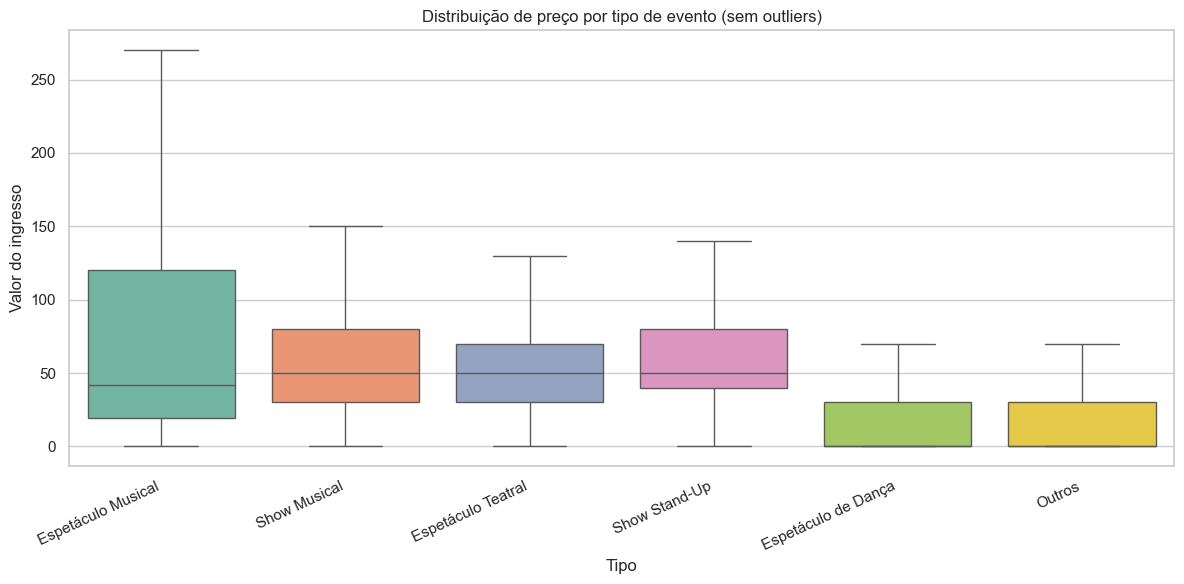

,count,median,mean
TIPO,,,
Espetáculo Teatral,81324,50.0,49.523019
Show Stand-Up,40923,50.0,57.408700
Show Musical,83919,50.0,57.975769
Espetáculo Musical,88738,42.0,69.769237
Outros,15677,0.0,15.216596
Espetáculo de Dança,19066,0.0,15.823101


In [15]:
# Preço por tipo (foco nos tipos com maior volume)
tipos_top = df_eda["TIPO"].value_counts().head(6).index
base_tipos = df_eda[df_eda["TIPO"].isin(tipos_top)].copy()

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=base_tipos,
    x="TIPO",
    y="VALOR_NUM",
    order=tipos_top,
    showfliers=False,
    palette="Set2",
)
plt.xticks(rotation=25, ha="right")
plt.title("Distribuição de preço por tipo de evento (sem outliers)")
plt.xlabel("Tipo")
plt.ylabel("Valor do ingresso")
plt.tight_layout()
plt.show()

base_tipos.groupby("TIPO")["VALOR_NUM"].agg(["count", "median", "mean"]).sort_values("median", ascending=False)

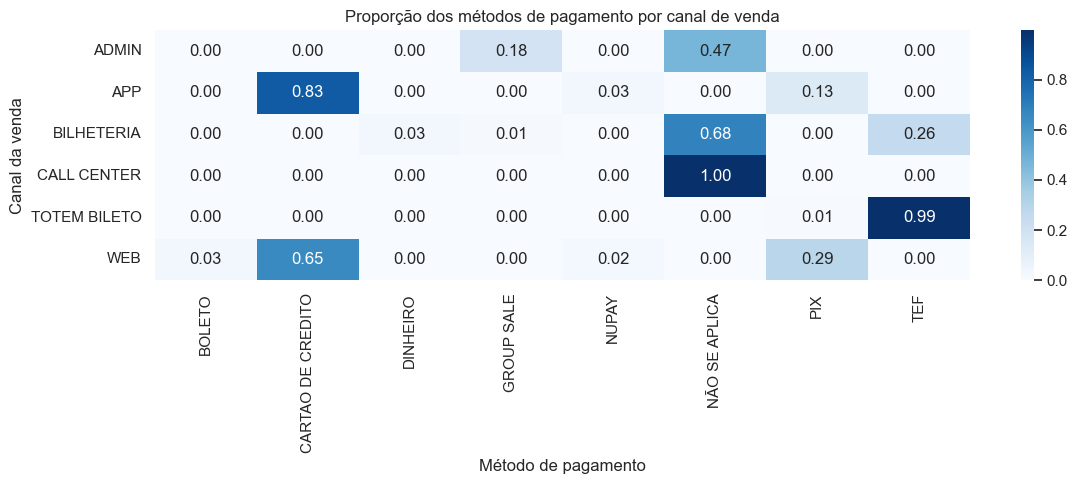

In [16]:
# Relação entre canal de venda e método de pagamento (proporção por canal)
ct = pd.crosstab(df_eda["CANAL DA VENDA"], df_eda["MÉTODO DE PAGAMENTO"], normalize="index")

# Seleciona os métodos mais frequentes para visualização legível
metodos_top = df_eda["MÉTODO DE PAGAMENTO"].value_counts().head(8).index
ct_plot = ct[ct.columns.intersection(metodos_top)]

plt.figure(figsize=(12, 5))
sns.heatmap(ct_plot, annot=True, fmt=".2f", cmap="Blues")
plt.title("Proporção dos métodos de pagamento por canal de venda")
plt.xlabel("Método de pagamento")
plt.ylabel("Canal da venda")
plt.tight_layout()
plt.show()

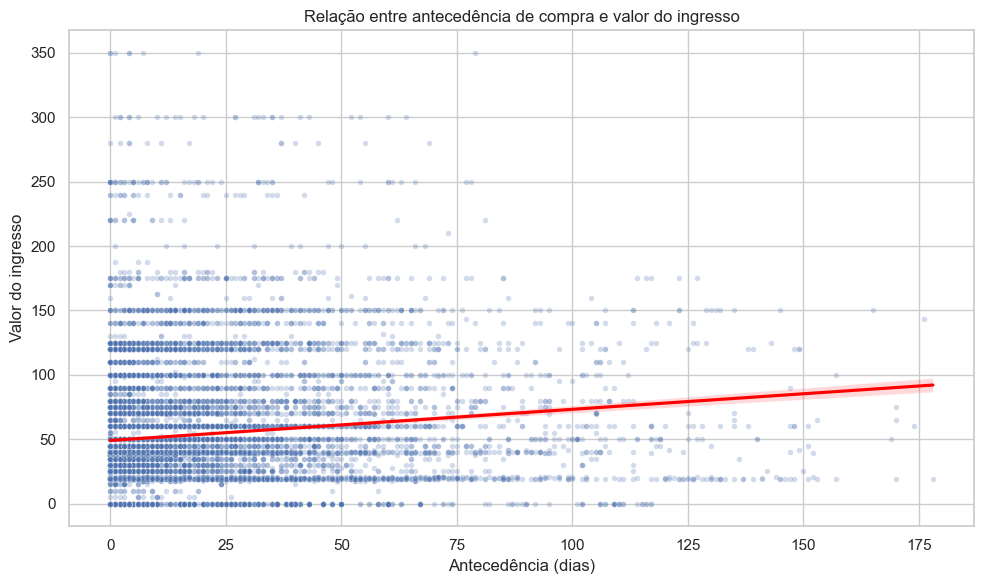

,ANTECEDENCIA_DIAS,VALOR_NUM
ANTECEDENCIA_DIAS,1.000000,0.128443
VALOR_NUM,0.128443,1.000000


In [17]:
# Antecedência de compra vs valor do ingresso (amostra para performance visual)
base_relacao = df_eda[["ANTECEDENCIA_DIAS", "VALOR_NUM"]].dropna().copy()
base_relacao = base_relacao[(base_relacao["ANTECEDENCIA_DIAS"] >= 0) & (base_relacao["ANTECEDENCIA_DIAS"] <= 180)]

amostra = base_relacao.sample(min(12000, len(base_relacao)), random_state=42)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=amostra, x="ANTECEDENCIA_DIAS", y="VALOR_NUM", alpha=0.25, s=16)
sns.regplot(data=amostra, x="ANTECEDENCIA_DIAS", y="VALOR_NUM", scatter=False, color="red")
plt.title("Relação entre antecedência de compra e valor do ingresso")
plt.xlabel("Antecedência (dias)")
plt.ylabel("Valor do ingresso")
plt.tight_layout()
plt.show()

amostra[["ANTECEDENCIA_DIAS", "VALOR_NUM"]].corr()

## 6) Sequenciamento e priorização da entrega

A entrega foi organizada em etapas sequenciais. Primeiro, foi realizada a importação e limpeza da base original. Em seguida, foi criado o dataset final para recomendação, estruturado com `user_id`, `item_id`, `ranking`, `valor_medio_ingresso` e `tipo_evento`.

Após a geração do CSV, o dataset foi carregado novamente no notebook para validação, descrição estatística e análise de balanceamento. Por fim, foram realizadas análises complementares da base original para apoiar possíveis evoluções futuras do sistema de recomendação.

A prioridade principal foi garantir a estrutura mínima exigida para filtragem colaborativa, com usuário, item e ranking. As variáveis adicionais foram mantidas como apoio para análises futuras e possíveis abordagens híbridas.

## 7) Conclusão

O dataset final foi estruturado para alimentar um sistema de recomendação, contendo `user_id`, `item_id`, `ranking`, `valor_medio_ingresso` e `tipo_evento`.

Como a base original não possui avaliações explícitas dos usuários, o `ranking` foi construído como feedback implícito. Nesta versão, ele representa a quantidade de dias distintos em que um usuário interagiu com determinado espetáculo, com limite máximo de 5.

Compras repetidas do mesmo usuário para o mesmo espetáculo na mesma data foram consideradas como uma única interação, reduzindo distorções causadas por múltiplos ingressos ou compras repetidas em uma mesma data.

A análise exploratória permitiu verificar a estrutura, a qualidade, o balanceamento e a esparsidade do dataset. Com isso, a base fica mais adequada para as próximas etapas de filtragem colaborativa e fatoração de matrizes.

## 8) Resumo das alterações realizadas na preparação dos dados na Sprint 2

Nesta etapa, foram realizadas mudanças na construção e validação do dataset final de recomendação, com o objetivo de deixar a base mais adequada para as próximas etapas de filtragem colaborativa e fatoração de matrizes.

As principais alterações realizadas foram:

- Inclusão da coluna `DATA_COMPRA_DT` na criação do dataset de recomendação.
- Criação da coluna `DATA_COMPRA_DIA`, considerando apenas a data da compra, sem o horário.
- Aplicação da regra de que compras do mesmo usuário, para o mesmo espetáculo e na mesma data contam como uma única interação.
- Recriação do `ranking` com base na quantidade de dias distintos em que o usuário interagiu com determinado espetáculo.
- Limitação do valor máximo do `ranking` em 5, reduzindo o impacto de outliers e interações muito altas.
- Atualização do significado do `ranking`, que deixou de representar quantidade bruta de compras e passou a representar dias distintos de interação.
- Validação de dados faltantes e linhas duplicadas no dataset final.
- Inclusão da verificação de pares duplicados entre `user_id` e `item_id`.
- Atualização dos gráficos de distribuição do ranking, usuários mais ativos e espetáculos mais populares.
- Correção da análise de densidade de interações por usuário e da curva de cauda longa dos itens.
- Atualização dos textos explicativos e conclusões para refletir as novas regras de preparação dos dados.
- Manutenção das variáveis `valor_medio_ingresso` e `tipo_evento` como informações complementares para futuras abordagens híbridas.

Com essas alterações, o dataset final passou a representar melhor as interações reais entre usuários e espetáculos, evitando distorções causadas por múltiplas compras na mesma data e por volumes extremos de interação. Assim, a base fica mais consistente para ser utilizada nas próximas etapas de modelagem do sistema de recomendação.